Raw image range: 3.6437846e-11 2.660699e-07
After max normalization: 0.00013694789 0.99999624


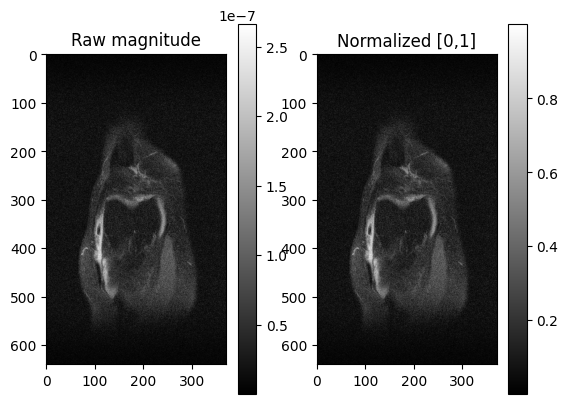

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---- Helper: centered inverse 2D FFT ----
def ifft2c(kspace):
    return np.fft.ifftshift(np.fft.ifft2(np.fft.fftshift(kspace)))

# ---- Load one file ----
data_dir = Path("/Users/mohamedzeyad/Desktop/fastmri/data/val")  # adjust path
file = sorted(data_dir.glob("*.h5"))[0]

with h5py.File(file, "r") as hf:
    kspace = hf["kspace"][10]   # pick one slice (index 10 for example)
    print("K-space shape:", kspace.shape)
# ---- Reconstruct image ----
image = np.abs(ifft2c(kspace))

print("Raw image range:", image.min(), image.max())

# ---- Normalize ----
image_norm = image / (image.max() + 1e-12)
print("After max normalization:", image_norm.min(), image_norm.max())

# ---- Visualize ----
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Raw magnitude")
plt.colorbar()

plt.subplot(1, 2, 2)
plt.imshow(image_norm, cmap="gray")
plt.title("Normalized [0,1]")
plt.colorbar()
plt.show()

In [16]:
file

array([[0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
       ...,
       [0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j]],
      dtype=complex64)

In [3]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---- Helper: centered inverse 2D FFT ----
def ifft2c(kspace):
    return np.fft.ifftshift(np.fft.ifft2(np.fft.fftshift(kspace)))

# ---- Load one file ----
data_dir = Path("/Users/mohamedzeyad/Desktop/fastmri/data/test")  # adjust path
file = sorted(data_dir.glob("*.h5"))[0]

with h5py.File(file, "r") as hf:
    for k, v in hf.items():
        print(f"{k}: {v.shape} {v.dtype}")



ismrmrd_header: () object
kspace: (37, 640, 368) complex64
mask: (368,) bool
